(lineage_curves)=

# Draw lineage curves and check candidate sinks

Fate probabilities say how strongly each cell connects to each endpoint, but not where a
lineage runs through the data. This page fits one smooth curve per lineage through the cells'
reduced coordinates, in the spirit of the principal curves of
[Slingshot](https://doi.org/10.1186/s12864-018-4772-0), draws the curves over a UMAP, and
places points on them. It also builds Slingshot's cluster tree, which proposes lineages, and
shows why its leaves are candidates to check rather than discovered fates.

## Open the prepared analysis

In [1]:
# Work with numeric arrays and tables.
import numpy as np
import pandas as pd

# Open count stores and run CyteArc analyses.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Download the prepared example store.
dataset = cytearc.cytebase.connect("cytearc_docs").download_dataset(
    name="bastidas-ponce_4K_pancreas-d15_rnaseq",
    destination="cytearc_datasets",
    zarr=True,
)

# Open the count store for this analysis.
ds = cytearc.DataStore(f"{dataset}/data.zarr", nthreads=4)

# Open the saved RNA analysis of the pancreas cells.
analysis_run = ds.pipeline.open(label="rna")

# Keep the graph and the full feature selection of the saved analysis.
graph = analysis_run["connectivity_map"]
all_features = analysis_run["feature_universe"]

Started: 2026-10-24T12:58:38.845803Z | Wall time: 8.089 s

## Propose lineages with a cluster tree

A cluster tree joins clusters by a minimum spanning tree. Its edge lengths compare cluster
centres relative to the clusters' spread, and the paths from a root cluster to the leaves
propose lineages. We build one over the published cell types, rooted at the Ductal cells.

In [2]:
# Read the published cell types of the graph's cells.
annotations = ds.cells.fetch("clusters", key="I")

# Freeze them as labels of the graph's cells.
cell_types = ds.snapshot_cluster_labels(
    "clusters", cell_selection=analysis_run["analysis_cell_selection"]
)

# Join the cell types by a minimum spanning tree rooted at the Ductal cells.
tree_ref = ds.trajectory.lineage_tree(graph, cell_types, root="Ductal")

# Load the tree.
tree = ds.trajectory.load_lineage_tree(tree_ref)

# Print each proposed lineage from the root to a leaf.
for path in tree.lineages:
    print(" > ".join(path))

Ductal > Ngn3 low EP > Ngn3 high EP > Pre-endocrine > Delta
Ductal > Ngn3 low EP > Ngn3 high EP > Pre-endocrine > Beta > Alpha > Epsilon


Started: 2026-10-24T12:58:46.939285Z | Wall time: 0.436 s

The trunk, Ductal to Ngn3 low EP to Ngn3 high EP to Pre-endocrine, follows the known
order. The endocrine fates do not: the tree chains Beta, Alpha, and Epsilon one after another.
These populations share an endocrine program and lie close together in the reduced space, and
a tree must join every cluster, so it runs one lineage through two endpoints. Draw the tree
over the saved UMAP:

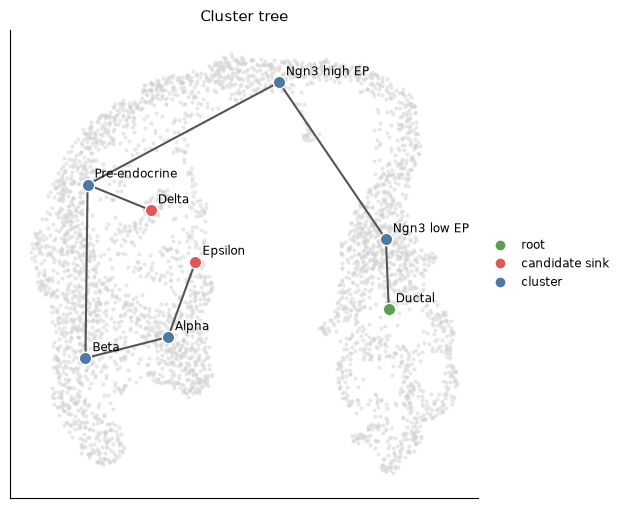

Started: 2026-10-24T12:58:47.379230Z | Wall time: 1.263 s

In [3]:
# Draw the tree with its root and candidate endpoints over the saved UMAP.
ds.plots.lineage_tree(tree=tree_ref, layout=analysis_run["umap"], figsize=(6.0, 5.0))

When the endpoints are known, holding them as ends makes them leaves: the tree first
spans the other clusters, then joins each end to its nearest cluster.

In [4]:
# Rebuild the tree with the four endocrine populations held as leaves.
fixed_ref = ds.trajectory.lineage_tree(
    graph, cell_types, root="Ductal", ends=["Alpha", "Beta", "Delta", "Epsilon"]
)

# Print the lineages of the constrained tree.
for path in ds.trajectory.load_lineage_tree(fixed_ref).lineages:
    print(" > ".join(path))

Ductal > Ngn3 low EP > Ngn3 high EP > Pre-endocrine > Alpha
Ductal > Ngn3 low EP > Ngn3 high EP > Pre-endocrine > Beta
Ductal > Ngn3 low EP > Ngn3 high EP > Pre-endocrine > Delta
Ductal > Ngn3 low EP > Ngn3 high EP > Pre-endocrine > Epsilon


Started: 2026-10-24T12:58:48.645539Z | Wall time: 0.380 s

The tree also depends on how finely the cells are clustered. Over the saved analysis's
computed clusters, rooted at the cluster that holds most Ductal cells:

In [5]:
# Read the computed clusters of the saved analysis.
computed = analysis_run.cells.fetch("clusters")

# Name each computed cluster by its most common published cell type.
majority = pd.crosstab(computed, annotations).idxmax(axis=1)

# Root the tree at the cluster that holds most Ductal cells.
root = pd.crosstab(computed, annotations)["Ductal"].idxmax()

# Build the tree over the computed clusters.
computed_tree = ds.trajectory.load_lineage_tree(
    ds.trajectory.lineage_tree(graph, analysis_run["clusters"], root=root)
)

# Print its lineages, naming every cluster by its majority cell type.
for path in computed_tree.lineages:
    print(" > ".join(f"{cluster} ({majority[cluster]})" for cluster in path))

2 (Ductal) > 10 (Ngn3 high EP) > 4 (Ngn3 high EP) > 6 (Pre-endocrine) > 5 (Pre-endocrine) > 1 (Beta) > 3 (Alpha) > 9 (Epsilon)
2 (Ductal) > 8 (Ductal) > 7 (Ductal) > 11 (Ductal)
2 (Ductal) > 10 (Ngn3 high EP) > 4 (Ngn3 high EP) > 6 (Pre-endocrine) > 5 (Pre-endocrine) > 12 (Delta)


Started: 2026-10-24T12:58:49.029133Z | Wall time: 0.444 s

With more clusters, the tree can add leaves that end inside a progenitor population,
such as the Ductal leaf here, because they follow cluster boundaries rather than fates, and it
still chains Beta, Alpha, and Epsilon.
Treat leaves as candidate endpoints and check them with markers, as in [](annotation.ipynb), before passing them to `trajectory.fate`.

## Fit fate-weighted lineage curves

We map the four endocrine fates as in [](lineage_dynamics.ipynb). A lineage curve is then the
fate-weighted mean of the cells' coordinates as a smooth function of their pseudotime rank
along the lineage: the share of the lineage's fate weight carried by cells earlier in
pseudotime. Cells near an endpoint weigh most in its curve, and cells of the shared trunk shape
every curve, so the curves share the trunk and part where the fate probabilities part.

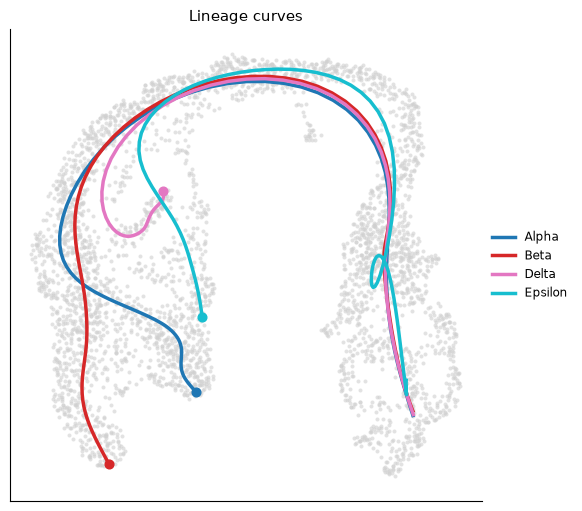

Started: 2026-10-24T12:58:49.476210Z | Wall time: 5.068 s

In [6]:
# Name the four candidate endocrine fates.
fates = ["Alpha", "Beta", "Delta", "Epsilon"]

# Mark the starting population and the pooled endpoints.
source = annotations == "Ductal"
sink = np.isin(annotations, fates)

# Share a total weight of -1 among source cells and +1 among endpoint cells.
source_sink_vector = np.zeros(len(annotations), dtype=float)
source_sink_vector[source] = -1.0 / source.sum()
source_sink_vector[sink] = 1.0 / sink.sum()

# Score pseudotime with the chosen source and endpoints.
pseudotime_ref = ds.trajectory.pseudotime(graph, ss_vec=source_sink_vector)

# Keep the selection of the scored cells.
scored_cells = ds.trajectory.load_pseudotime(pseudotime_ref).cell_selection

# Freeze the published cell types of those cells as sink labels.
cell_types = ds.snapshot_cluster_labels("clusters", cell_selection=scored_cells)

# Map how strongly each cell connects to each fate.
fate_ref = ds.trajectory.fate(pseudotime_ref, cell_types, sinks=fates)

# Fit one curve per lineage through the coordinates the graph was built on.
curves_ref = ds.trajectory.curves(fate_ref)

# Draw the curves over the saved UMAP.
ds.plots.lineage_curves(
    curves=curves_ref, layout=analysis_run["umap"], figsize=(6.0, 5.0)
)

The curves are fitted in the 15 principal components that built the graph. To draw a
curve in the UMAP, the cells' UMAP positions are averaged along the curve with the lineage's
fate weights and smoothed, so the drawing follows where the weighted cells lie in the UMAP.
Distances in a UMAP are distorted, so read the drawing for the order and the parting of the
lineages, not for lengths.

## Read positions along the curves

Every scored cell is projected onto every curve. Its progress is the position of the nearest
curve point, from zero at the start to one at the endpoint, and its distance is how far it lies
from the curve.

In [7]:
# Load the curves and each cell's position on them.
curves = ds.trajectory.load_curves(curves_ref)

# Tabulate the median progress of each cell type along every lineage.
pd.DataFrame(curves.progress, columns=fates).groupby(annotations).median().round(2)

,Alpha,Beta,Delta,Epsilon
Alpha,0.78,0.79,0.75,1.00
Beta,0.70,0.83,0.75,0.96
Delta,0.70,0.82,0.79,0.94
Ductal,0.11,0.13,0.12,0.21
Epsilon,0.64,0.75,0.72,0.90
Ngn3 high EP,0.33,0.40,0.36,0.58
Ngn3 low EP,0.18,0.22,0.20,0.28
Pre-endocrine,0.47,0.57,0.49,0.76


Started: 2026-10-24T12:58:54.548054Z | Wall time: 0.253 s

Progress grows from the Ductal cells through the progenitors on every lineage. Because
progress counts fate weight, an endpoint population fills the last stretch of its own
lineage: the Alpha cells carry the last 45% of the Alpha lineage's weight, so their median is
about 0.8. Cells far from a curve land on its nearest end, which is why Alpha cells
reach the end of the Epsilon curve. Read progress together with the distance from each curve:

In [8]:
# Tabulate the median distance of each cell type from every curve.
pd.DataFrame(curves.distance, columns=fates).groupby(annotations).median().round(1)

,Alpha,Beta,Delta,Epsilon
Alpha,6.1,14.8,17.5,11.6
Beta,14.8,5.4,16.7,19.5
Delta,17.7,17.2,4.9,16.7
Ductal,7.6,7.4,7.5,7.2
Epsilon,13.8,19.1,16.9,7.0
Ngn3 high EP,7.6,6.6,7.1,5.5
Ngn3 low EP,7.7,7.7,7.6,7.5
Pre-endocrine,6.7,6.1,8.6,13.3


Started: 2026-10-24T12:58:54.803271Z | Wall time: 0.013 s

Ductal and Ngn3 low EP cells lie about equally close to every curve, because the curves
share the trunk. From the Pre-endocrine cells on, where the lineages part, the distances
differ, and endpoint cells lie much closer to their own lineage's curve than to the others.
Distance is geometric evidence of where a cell lies; unlike a fate probability, it says nothing about
where the graph's random walks lead.

## Place other points on the curves

`project` places any coordinates of the same space on the curves, such as new cells projected
into these principal components with the same loadings. Here we place the centroid of each
cell type.

In [9]:
# Read the coordinates that the curves were fitted in.
coordinates = np.asarray(ds.artifacts.load(curves.coordinates)["data"][:])

# Average the coordinates of each cell type.
centroids = pd.DataFrame(coordinates).groupby(annotations).mean()

# Place each centroid on every curve.
placed = curves.project(centroids.to_numpy())

# Tabulate the fitted pseudotime of each centroid along every lineage.
table = pd.DataFrame(placed.pseudotime, index=centroids.index, columns=fates).round(2)

# Name the curve that each centroid lies closest to.
table["closest curve"] = np.asarray(fates)[placed.distance.argmin(axis=1)]
table

,Alpha,Beta,Delta,Epsilon,closest curve
Alpha,0.97,0.97,0.96,0.97,Alpha
Beta,0.97,0.98,0.96,0.97,Beta
Delta,0.97,0.97,0.96,0.97,Delta
Ductal,0.01,0.01,0.01,0.01,Epsilon
Epsilon,0.97,0.96,0.96,0.96,Epsilon
Ngn3 high EP,0.50,0.50,0.50,0.50,Alpha
Ngn3 low EP,0.05,0.04,0.04,0.04,Delta
Pre-endocrine,0.89,0.89,0.88,0.84,Beta


Started: 2026-10-24T12:58:54.819138Z | Wall time: 0.864 s

Each centroid receives the pseudotime of its nearest point on every curve. The
progenitor centroids land in order along the shared trunk. Every endpoint centroid lands late
on every curve, because pseudotime levels off near the endpoints, but each lies closest to its
own lineage's curve. Near the start the closest curve means little: the curves share the
trunk, so the Ductal centroid lies at nearly the same distance from every curve. Coordinates
from another dataset need the same reduction: project them
with these principal components' loadings, centring, and scaling first.

## Common mistakes and limitations

- Treating tree leaves as fates: a tree must join every cluster, so similar endpoints can be
  chained and extra clusters add leaves. Check leaves with markers before using them as sinks.
- Reading a curve as the path of individual cells: a curve summarizes where fate-weighted
  cells lie, and inside a compact cluster it is an average position.
- Measuring along a UMAP drawing: the curves are fitted in the principal components, and the
  UMAP distorts distances.
- Projecting coordinates of another space: points must be reduced the same way as the cells
  the curves were fitted to.

See [](trajectory_validation.md) for checks of the endpoints and the graph behind these
curves.